In [1]:
from pathlib import Path
import pandas as pd

CSV_PATH = Path("../data/raw/historique_final_version.csv")

with CSV_PATH.open("rb") as f:
    nb_lignes = sum(1 for _ in f)
print(f"{nb_lignes:,} lignes dans le fichier".replace(",", " "))

8 974 624 lignes dans le fichier


In [2]:
df = pd.read_csv(CSV_PATH, header=None)
print(df.shape)
df.head()

(8974624, 8)


,0,1,2,3,4,5,6,7
0,2026-10-16T11:52Z,10003,17,1,1,Hauteville - Bonne Nouvelle,"48.87077,2.34965",True
1,2026-10-16T11:52Z,10004,48,1,4,Metz - Faubourg Saint-Denis,"48.87089,2.35352",True
2,2026-10-16T11:52Z,10005,17,0,9,Petites Ecuries - Faubourg Poissonnière,"48.87397,2.34839",True
3,2026-10-16T11:52Z,10006,28,3,20,Petites Ecuries - Faubourg Saint-Denis,"48.87287,2.35422",True
4,2026-10-16T11:52Z,10008,18,4,2,Cité Riverin - Château d'Eau,"48.87070,2.35874",True


In [3]:
# Renommer les colonnes et convertir les types de données
COLONNES = [
    "horodatage", "station_code", "capacity", "velo_meca", "velo_elec",
    "station_name", "coordonnees", "operative",
]

df = pd.read_csv(CSV_PATH, header=None, names=COLONNES)
df["horodatage"] = pd.to_datetime(df["horodatage"], utc=True)

# fin de la collecte : on garde les relevés avant le 7 novembre 2026 à 0h
df = df[df["horodatage"] < pd.Timestamp("2026-11-07 00:00", tz="UTC")]
df[["latitude", "longitude"]] = df["coordonnees"].str.split(",", expand=True).astype(float)
df = df.drop(columns="coordonnees")

In [4]:
# Fusion des colonnes "velo_meca" et #velo_elec" pour créer une nouvelle colonne "available" 
df["available"] = df["velo_meca"] + df["velo_elec"]

In [5]:
# Ecarter les stations en dehors de Paris 
dans_paris = df["latitude"].between(48.815, 48.902) & df["longitude"].between(2.224, 2.470)
df = df[dans_paris].copy()

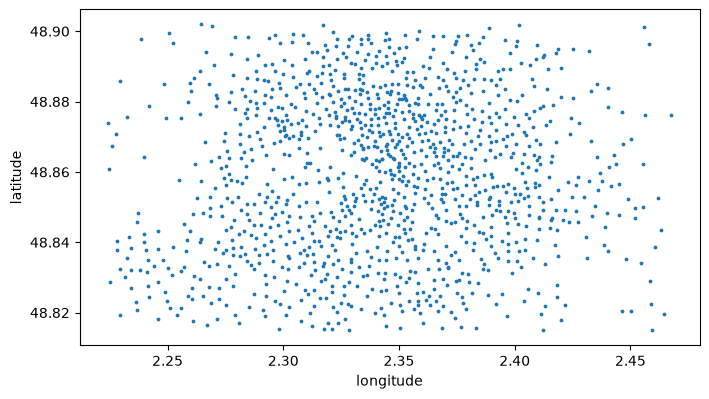

In [6]:
# Voir ce que ça donne sur une carte 
import numpy as np

stations = df.drop_duplicates("station_code")
ax = stations.plot.scatter(x="longitude", y="latitude", s=3, figsize=(8, 8))
ax.set_aspect(1 / np.cos(np.radians(48.86)))

In [7]:
# Suppressions des stations à capacité nulle (0)
df = df[df["capacity"] > 0].copy()

In [8]:
# Vérification 
print(df["capacity"].min()) 
print((df["capacity"] == 0).sum())

1
0


In [9]:
# Je vais chercher à isoler les cas problématiques, c-à-d les stations où la capacité est inférieur aux nombres de vélos dispo
anomalies = df[df["available"] > df["capacity"]].copy()
anomalies["exces"] = anomalies["available"] - anomalies["capacity"]

print(f"{len(anomalies):,} lignes sur {len(df):,} ({len(anomalies) / len(df):.2%})")
print(f"{anomalies['station_code'].nunique()} stations sur {df['station_code'].nunique()}")
anomalies["exces"].describe()

16,501 lignes sur 6,954,399 (0.24%)
22 stations sur 1217


count    16501.000000
mean         9.447185
std          8.134041
min          1.000000
25%          3.000000
50%          7.000000
75%         14.000000
max         40.000000
Name: exces, dtype: float64

In [10]:
# Trouver les cas les plus extrêmes 
anomalies.sort_values("exces", ascending=False).head(10)[
    ["horodatage", "station_code", "station_name", "capacity", "velo_meca", "velo_elec", "operative", "exces"]
]

,horodatage,station_code,station_name,capacity,velo_meca,velo_elec,operative,exces
4506346,2026-10-27 12:20:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,60,22,True,40
4507865,2026-10-27 12:25:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,60,22,True,40
4491156,2026-10-27 11:30:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,60,22,True,40
4492675,2026-10-27 11:35:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,60,22,True,40
4494194,2026-10-27 11:40:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,60,22,True,40
4501789,2026-10-27 12:05:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,60,22,True,40
4503308,2026-10-27 12:10:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,60,22,True,40
4500270,2026-10-27 12:00:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,60,22,True,40
4504827,2026-10-27 12:15:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,60,22,True,40
4475966,2026-10-27 10:40:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,61,21,True,40


In [11]:
# 1. Lignes entièrement identiques (toutes les occurrences marquées)
full_dups = df[df.duplicated(keep=False)]

In [12]:
# 2. Doublons sur la clé logique : même station au même instant
key_dups = df[df.duplicated(subset=["horodatage", "station_code"], keep=False)]
key_dups = key_dups.sort_values(["station_code", "horodatage"])

In [13]:
print(f"Lignes identiques : {len(full_dups)}")
print(f"Doublons (timestamp, station_id) : {len(key_dups)}")
print(key_dups)

Lignes identiques : 0
Doublons (timestamp, station_id) : 0
Empty DataFrame
Columns: [horodatage, station_code, capacity, velo_meca, velo_elec, station_name, operative, latitude, longitude, available]
Index: []


In [14]:
# 3. Pour nettoyer en gardant la première occurrence mais pas besoin parce que pas de doublons
df = df.drop_duplicates(subset=["horodatage", "station_code"], keep="first")

In [15]:
# trie selon le code de station et l'heure pour compter la disponibilité il y a 30 min
df = df.sort_values(["station_code", "horodatage"]).reset_index(drop=True)

# On cherche la ligne exactement il y a 30 min
past = df[["station_code", "horodatage", "available"]].copy()
past["horodatage"] = past["horodatage"] + pd.Timedelta(minutes=30)
past = past.rename(columns={"available": "available_last_30"})

df = df.merge(past, on=["station_code", "horodatage"], how="left")
# pour convertir en Int et pas float
df["available_last_30"] = df["available_last_30"].astype("Int64")

Création d'une variable cible




In [16]:
# trie selon le code de station et l'heure pour compter la disponibilité dans 30 min
df = df.sort_values(["station_code", "horodatage"]).reset_index(drop=True)

In [17]:
# On cherche la ligne exactement 30 min plus tard
future = df[["station_code", "horodatage", "available"]].copy()
future["horodatage"] = future["horodatage"] - pd.Timedelta(minutes=30)
future = future.rename(columns={"available": "available_t30"})

In [18]:
df = df.merge(future, on=["station_code", "horodatage"], how="left")
# pour convertir en Int et pas float
df["available_t30"] = df["available_t30"].astype("Int64")

In [19]:
# Pour répérer les nan pour voir la proportion des données manquantes
n_na = df["available_t30"].isna().sum()
print(f"Avaliabe in 30 minutes is NA : {n_na} / {len(df)} ({n_na / len(df):.1%})")

n_na = df["available_last_30"].isna().sum()
print(f"Avaliabe last 30 minutes is NA : {n_na} / {len(df)} ({n_na / len(df):.1%})")

Avaliabe in 30 minutes is NA : 261217 / 6954399 (3.8%)
Avaliabe last 30 minutes is NA : 261217 / 6954399 (3.8%)


In [20]:
# ecarter des valeurs manquantes après le shift
df = df.dropna(subset=["available_t30", "available_last_30"]).reset_index(drop=True)

In [21]:
# introduire la tendance
df["delta_t30"] = df["available"] - df["available_last_30"]

# Catégorie lisible le stock monte, baisse ou reste stable
df["tendance"] = pd.cut(
    df["delta_t30"],
    bins=[-float("inf"), -1, 0, float("inf")],
    labels=["baisse", "stable", "hausse"],
)

In [22]:
# introduire representation cyclique de heure
heure_dec = df["horodatage"].dt.hour + df["horodatage"].dt.minute / 60

df["heure_sin"] = np.sin(2 * np.pi * heure_dec / 24)
df["heure_cos"] = np.cos(2 * np.pi * heure_dec / 24)

In [23]:
# introduire is weekend
df["is_weekend"] = df["horodatage"].dt.dayofweek >= 5
df

,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,available_last_30,available_t30,delta_t30,tendance,heure_sin,heure_cos,is_weekend
0,2026-10-16 13:50:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,14,7,11,7,hausse,-0.461749,-0.887011,False
1,2026-10-16 13:55:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,13,7,11,6,hausse,-0.480989,-0.876727,False
2,2026-10-16 14:05:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,13,14,10,-1,baisse,-0.518773,-0.854912,False
3,2026-10-16 14:10:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,13,14,13,-1,baisse,-0.537300,-0.843391,False
4,2026-10-16 14:15:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,13,14,14,-1,baisse,-0.555570,-0.831470,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6510919,2026-11-06 23:00:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,0,stable,-0.258819,0.965926,False
6510920,2026-11-06 23:05:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,0,stable,-0.237686,0.971342,False
6510921,2026-11-06 23:10:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,0,stable,-0.216440,0.976296,False
6510922,2026-11-06 23:15:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,0,stable,-0.195090,0.980785,False


Dynamique Globale







In [24]:
print(df["delta_t30"].describe())
print(df["tendance"].value_counts(normalize=True))

count    6510924.0
mean      0.002403
std       2.152927
min          -65.0
25%           -1.0
50%            0.0
75%            1.0
max           45.0
Name: delta_t30, dtype: Float64
tendance
stable    0.404937
baisse    0.298504
hausse    0.296559
Name: proportion, dtype: float64


In [25]:
# voir les lignes ou la delta min -65
df[df["delta_t30"] == df["delta_t30"].min()]

,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,available_last_30,available_t30,delta_t30,tendance,heure_sin,heure_cos,is_weekend
2330555,2026-10-23 20:20:00+00:00,12108,66,0,0,Bercy.,True,48.83997,2.37886,0,65,0,-65,baisse,-0.819152,0.573576,False
2330556,2026-10-23 20:25:00+00:00,12108,66,0,0,Bercy.,True,48.83997,2.37886,0,65,0,-65,baisse,-0.806445,0.591310,False
2330557,2026-10-23 20:30:00+00:00,12108,66,0,0,Bercy.,True,48.83997,2.37886,0,65,0,-65,baisse,-0.793353,0.608761,False


Dynamique par station

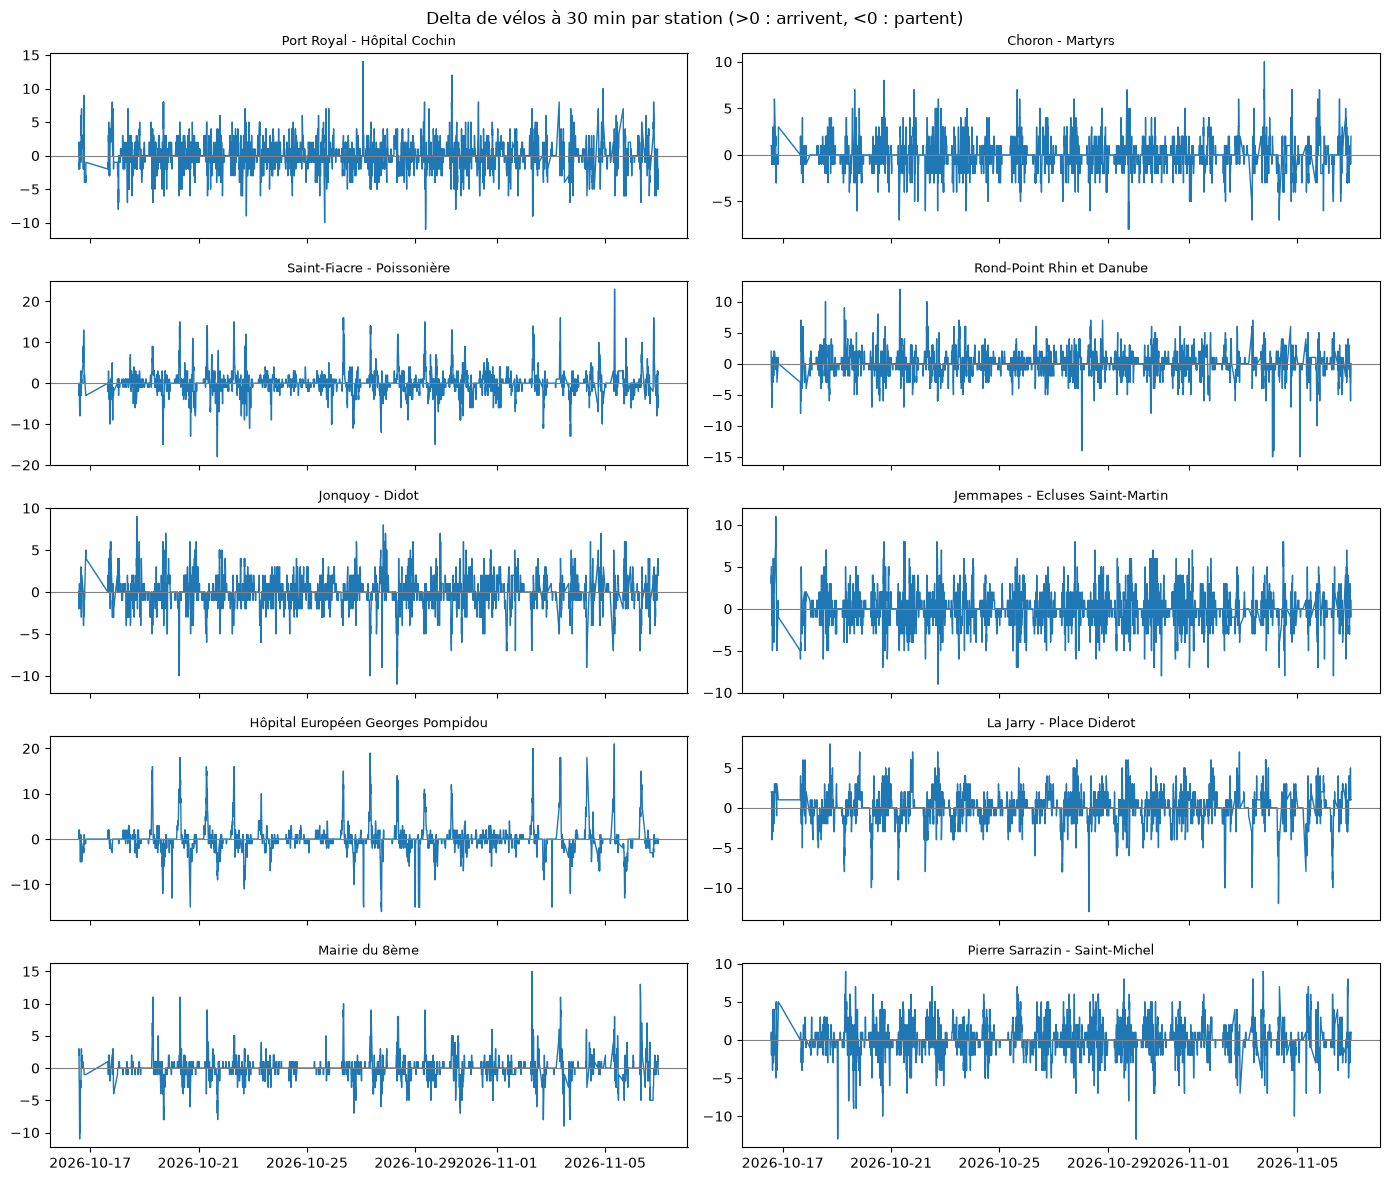

In [26]:
import matplotlib.pyplot as plt

# 10 stations au hasard (random_state fixe pour retrouver les mêmes)
codes = df["station_code"].drop_duplicates().sample(10, random_state=42)

fig, axes = plt.subplots(5, 2, figsize=(14, 12), sharex=True)

for ax, code in zip(axes.flat, codes):
    d = df[df["station_code"] == code].sort_values("horodatage")
    nom = d["station_name"].iloc[0]
    ax.plot(d["horodatage"], d["delta_t30"], linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(nom, fontsize=9)

fig.suptitle("Delta de vélos à 30 min par station (>0 : arrivent, <0 : partent)")
plt.tight_layout()
plt.show()

Dynamique par l'heure


<Axes: title={'center': 'Delta moyen à 30 min par heure (Paris)'}, xlabel='heure'>

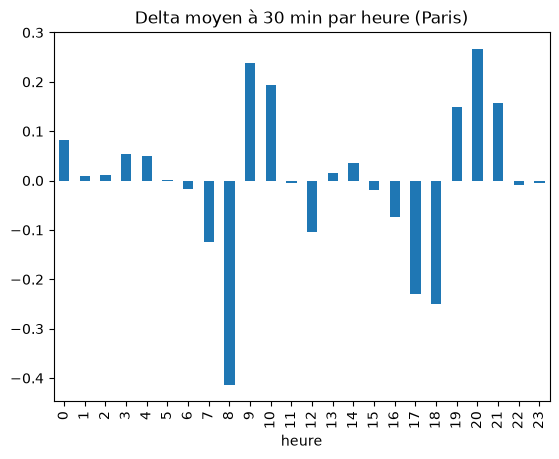

In [27]:
# introduction d'une colonne heure qui signifie l'heure de Paris pour les statistiques en bonne timezone
df["heure"] = df["horodatage"].dt.tz_convert("Europe/Paris").dt.hour
profil_horaire = df.groupby("heure")["delta_t30"].mean()
profil_horaire.plot(kind="bar", title="Delta moyen à 30 min par heure (Paris)")

Les rush hours


En semaine

Rush hours (semaine) : [8, 9, 17, 18, 19, 20]


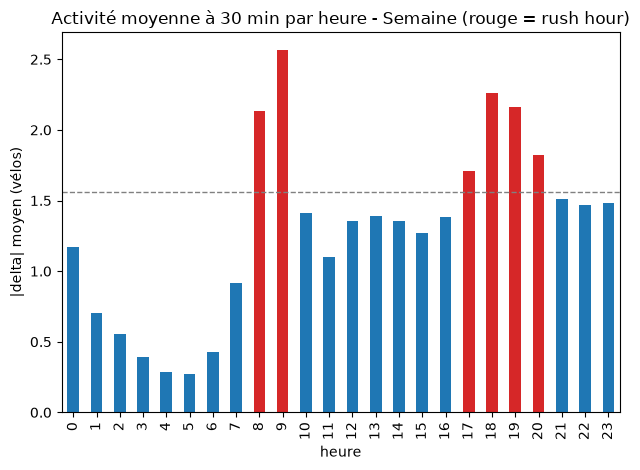

In [28]:
# valeur absolue de delta
df["delta_abs"] = df["delta_t30"].abs()
semaine = df[~df["is_weekend"]]

# Activité moyenne par heure
activite = semaine.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
print("Rush hours (semaine) :", rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure - Semaine (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")
plt.tight_layout()
plt.show()

En weekend

Rush hours (week-end) : [14, 15, 16, 17, 18, 19]


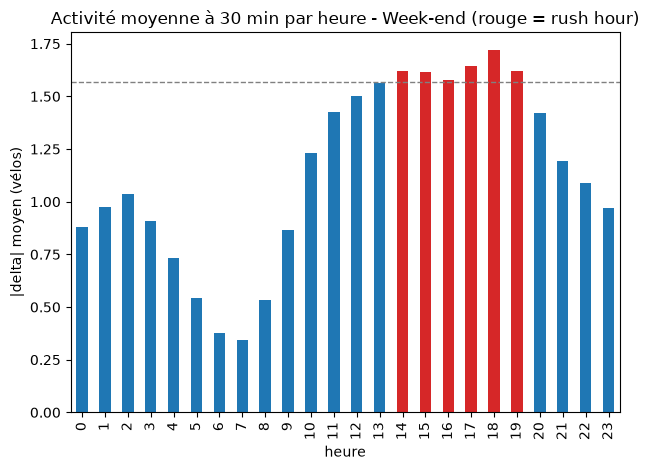

In [29]:
weekend = df[df["is_weekend"]]

# Activité moyenne par heure
activite = weekend.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
weekend_rush_hours = rush_hours
print("Rush hours (week-end) :", weekend_rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure - Week-end (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")
plt.tight_layout()
plt.show()

Rush hours : [8, 9, 17, 18, 19, 20]


Text(0, 0.5, '|delta| moyen (vélos)')

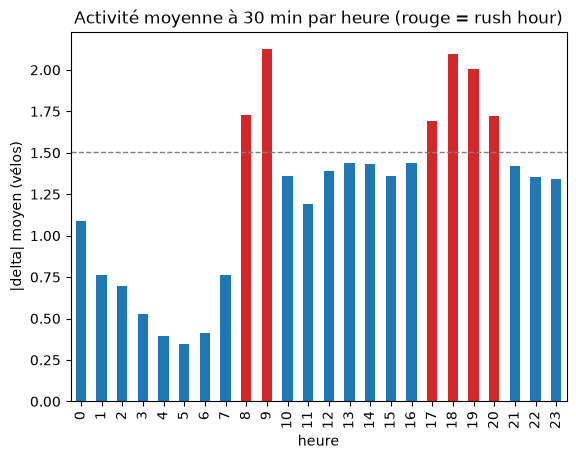

In [30]:
# Activité moyenne par heure
activite = df.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
week_rush_hours = rush_hours
print("Rush hours :", week_rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")

In [31]:
# introduction de rush hour chaque ligne
df["is_rush_hour"] = (
    (df["is_weekend"] & df["heure"].isin(weekend_rush_hours))
    | (~df["is_weekend"] & df["heure"].isin(week_rush_hours))
)

Les données météo

In [32]:
METEO_CSV_PATH = Path("../data/meteo_paris.csv")

with METEO_CSV_PATH.open("rb") as f:
    nb_lignes = sum(1 for _ in f)
print(f"{nb_lignes:,} lignes dans le fichier".replace(",", " "))

2 209 lignes dans le fichier


In [33]:
meteo = pd.read_csv(METEO_CSV_PATH)
print(meteo.shape)
meteo.head()

(2208, 8)


,date,temperature_2m,apparent_temperature,precipitation,weather_code,wind_speed_10m,rain,weather_label
0,2026-10-16 00:00:00+00:00,16.319500,16.440550,0.0,0.0,5.815978,0.0,Clear sky
1,2026-10-16 00:15:00+00:00,16.269500,16.389246,0.0,1.0,6.151683,0.0,Mainly clear
2,2026-10-16 00:30:00+00:00,16.219501,16.339570,0.0,1.0,6.034700,0.0,Mainly clear
3,2026-10-16 00:45:00+00:00,16.219501,16.339570,0.0,1.0,6.034700,0.0,Mainly clear
4,2026-10-16 01:00:00+00:00,16.169500,16.272877,0.0,1.0,6.034700,0.0,Mainly clear


In [34]:
meteo = meteo.rename(columns={"date": "horodatage"})
meteo["horodatage"] = pd.to_datetime(meteo["horodatage"], utc=True)
meteo.columns.tolist()

['horodatage',
 'temperature_2m',
 'apparent_temperature',
 'precipitation',
 'weather_code',
 'wind_speed_10m',
 'rain',
 'weather_label']

In [35]:
cols_continues = ["temperature_2m", "wind_speed_10m"]
cols_cumul = ["precipitation", "rain"]
cols_label = ["weather_label"]
cols_meteo = cols_continues + cols_cumul + cols_label

m = (meteo.drop_duplicates("horodatage")
       .sort_values("horodatage")
       .set_index("horodatage"))

# L'index porte le nom horodatage
heure_cibles = pd.DatetimeIndex(df["horodatage"].unique(), name="horodatage").sort_values()
index_union = m.index.union(heure_cibles)
base = pd.DataFrame({"horodatage": heure_cibles})

# on interpole des colonnes avec valeur lineeaires
interp = (m[cols_continues].reindex(index_union)
          .interpolate(method="time", limit_area="inside")
          .reindex(heure_cibles))

# pluie et precipitations ce sont des données accumulées delta de 15 min
cumul = pd.merge_asof(
    base, m[cols_cumul].reset_index(),
    on="horodatage", direction="backward", tolerance=pd.Timedelta(minutes=15),
).set_index("horodatage")

# etiquettes le plus proche de 8 mins
label = pd.merge_asof(
    base, m[cols_label].reset_index(),
    on="horodatage", direction="nearest", tolerance=pd.Timedelta(minutes=8),
).set_index("horodatage")

meteo_aligned = pd.concat([interp, cumul, label], axis=1)
meteo_aligned.index.name = "horodatage"          # sécurité
df = df.merge(meteo_aligned.reset_index(), on="horodatage", how="left")

In [36]:
print(df[cols_meteo].isna().mean()) # si 0 partout c'est bien
echantillon = df.sample(100, random_state=42).sort_values("horodatage")
echantillon

temperature_2m    0.0
wind_speed_10m    0.0
precipitation     0.0
rain              0.0
weather_label     0.0
dtype: float64


,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,...,heure_cos,is_weekend,heure,delta_abs,is_rush_hour,temperature_2m,wind_speed_10m,precipitation,rain,weather_label
5121889,2026-10-16 15:15:00+00:00,20032,26,1,1,Square des Amandiers,True,48.86616,2.38913,2,...,-0.659346,False,17,2,True,20.219501,10.739833,0.0,0.0,Overcast
5363171,2026-10-17 15:40:00+00:00,21003,39,13,7,Jean Jaurès - Jean Baptiste Clément,True,48.84576,2.23697,20,...,-0.573576,True,17,1,True,15.252833,15.255671,0.0,0.0,Overcast
6339702,2026-10-18 19:00:00+00:00,41602,32,6,5,Place Charles Digeon,True,48.84354,2.41843,11,...,0.258819,True,21,0,False,10.419499,3.096837,0.0,0.0,Partly cloudy
4109049,2026-10-19 01:50:00+00:00,17029,37,7,3,Pierre Demours - Laugier,True,48.88131,2.29485,10,...,0.887011,False,3,0,False,7.386167,1.568085,0.0,0.0,Partly cloudy
2414978,2026-10-19 02:20:00+00:00,12151,60,0,2,Gare de Lyon - Place Louis Armand,True,48.84552,2.37265,2,...,0.819152,False,4,3,False,7.052833,1.484318,0.0,0.0,Mainly clear
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6274887,2026-11-06 05:35:00+00:00,35013,20,0,5,Guillaume Tell - Parc Henri Barbusse,True,48.88959,2.41989,5,...,0.108867,False,6,1,False,7.552833,3.436455,0.0,0.0,Overcast
4044177,2026-11-06 07:05:00+00:00,17016,31,8,16,Brochant - Square des Batignolles,True,48.88819,2.31686,24,...,-0.279829,False,8,1,True,7.286167,2.547199,0.0,0.0,Overcast
3631401,2026-11-06 08:50:00+00:00,15201,38,13,5,Place Amédée Gordini - Lefebvre,True,48.83062,2.29206,18,...,-0.675590,False,9,0,True,8.186167,4.610250,0.0,0.0,Overcast
1824800,2026-11-06 15:55:00+00:00,10208,30,1,5,Buisson Saint-Louis - Saint-Maur,True,48.87227,2.37333,6,...,-0.518773,False,16,4,False,13.302833,5.525397,0.0,0.0,Partly cloudy


In [37]:
# derniere normalisation des valeurs de meteo
cols_num = ["temperature_2m", "wind_speed_10m", "precipitation", "rain"]
df[cols_num] = df[cols_num].apply(pd.to_numeric, errors="coerce").astype("float64").round(2)

## La proximité entre toutes les stations

In [38]:
# Les Fonctions
RAYON_TERRE_M = 6_371_000
RAYON_VOISINAGE_M = 300


def table_stations(df: pd.DataFrame) -> pd.DataFrame:
    # Renvoie une ligne par station avec ses coordonnées.
    return (
        df.groupby("station_code")[["latitude", "longitude"]]
        .first()
        .reset_index()
    )


def matrice_distances_m(latitudes: np.ndarray, longitudes: np.ndarray) -> np.ndarray:
    # Distance en mètres entre chaque paire de points (formule de haversine).
    lat = np.radians(latitudes)
    lon = np.radians(longitudes)
    d_lat = lat[:, None] - lat[None, :]
    d_lon = lon[:, None] - lon[None, :]
    a = (
        np.sin(d_lat / 2) ** 2
        + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(d_lon / 2) ** 2
    )
    return 2 * RAYON_TERRE_M * np.arcsin(np.sqrt(a))


def stations_voisines(stations: pd.DataFrame, rayon_m: float = RAYON_VOISINAGE_M) -> pd.DataFrame:
    # Renvoie les paires de stations voisines 
    dist = matrice_distances_m(
        stations["latitude"].to_numpy(), stations["longitude"].to_numpy()
    )
    np.fill_diagonal(dist, np.inf)  # une station n'est pas sa propre voisine
    i, j = np.where(dist <= rayon_m)
    codes = stations["station_code"].to_numpy()
    return pd.DataFrame(
        {"station_code": codes[i], "voisin_code": codes[j], "distance_m": dist[i, j].round(1)}
    )

In [39]:
# Utilisation
stations = table_stations(df)
paires = stations_voisines(stations, rayon_m=300)

stations["nb_voisins"] = (
    stations["station_code"].map(paires["station_code"].value_counts()).fillna(0).astype(int)
)

print(f"{len(paires):,} paires de voisines")
print(stations["nb_voisins"].describe())
print((stations["nb_voisins"] == 0).sum(), "stations sans voisine")

2,822 paires de voisines
count    1217.000000
mean        2.318817
std         1.835393
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         9.000000
Name: nb_voisins, dtype: float64
210 stations sans voisine


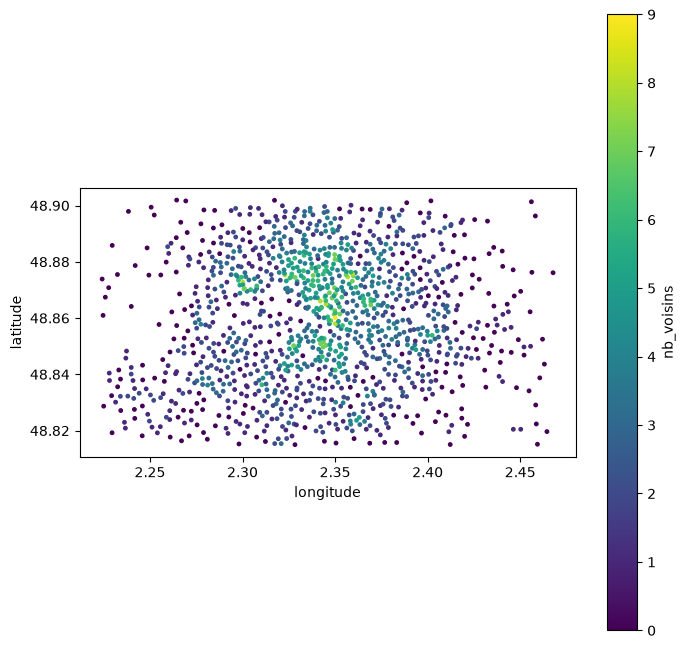

In [40]:
# Voir le résultat sur une carte
ax = stations.plot.scatter(
    x="longitude", y="latitude", c="nb_voisins", cmap="viridis", s=6, figsize=(8, 8)
)
ax.set_aspect(1 / np.cos(np.radians(48.86)))

In [41]:
# Ajout du nom de la station et le nom du voisin pour rendre la table lisible
paires_lisibles = paires.merge(
    df[['station_code', 'station_name']].drop_duplicates(), 
    on='station_code', 
    how='left'
).merge(
    df[['station_code', 'station_name']].drop_duplicates(), 
    left_on='voisin_code', 
    right_on='station_code', 
    suffixes=('', '_voisin'),
    how='left'
)[['station_name', 'station_name_voisin', 'distance_m']]

# Afficher les 10 premières paires avec de vrais noms
print(paires_lisibles.head(10))

                    station_name                    station_name_voisin  \
0  Quai de l'Horloge - Pont Neuf                Pont de Lodi - Dauphine   
1   Victoria - Place du Chatelet                   Saint-Denis - Rivoli   
2   Victoria - Place du Chatelet                   Halles - Bourdonnais   
3   Victoria - Place du Chatelet  Lavandieres Sainte Opportune - Rivoli   
4   Victoria - Place du Chatelet                     Saint-Bon - Rivoli   
5           Saint-Denis - Rivoli           Victoria - Place du Chatelet   
6           Saint-Denis - Rivoli                   Halles - Bourdonnais   
7           Saint-Denis - Rivoli                     Pont Neuf - Rivoli   
8           Saint-Denis - Rivoli               Cossonnerie - Sébastopol   
9           Saint-Denis - Rivoli  Lavandieres Sainte Opportune - Rivoli   

   distance_m  
0       237.9  
1       131.6  
2       281.4  
3       145.1  
4       241.4  
5       131.6  
6       197.0  
7       289.2  
8       282.4  
9        82.0 

In [42]:
print(f"{len(paires):,} paires, {stations['station_code'].nunique()} stations")
print(stations["nb_voisins"].describe())
print((stations["nb_voisins"] == 0).sum(), "stations sans voisine")

2,822 paires, 1217 stations
count    1217.000000
mean        2.318817
std         1.835393
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         9.000000
Name: nb_voisins, dtype: float64
210 stations sans voisine


In [43]:
# Vérification que les paires sont symétriques 
couples = set(zip(paires["station_code"], paires["voisin_code"]))
asymetriques = [(a, b) for a, b in couples if (b, a) not in couples]
print(len(asymetriques), "paires non symétriques")  # doit afficher 0

0 paires non symétriques


In [44]:
# Code pour choisir le rayon de voisinage le plus pertinent
dist = matrice_distances_m(
    stations["latitude"].to_numpy(), stations["longitude"].to_numpy()
)
np.fill_diagonal(dist, np.inf)

plus_proche = pd.Series(dist.min(axis=1))
print(plus_proche.describe(percentiles=[0.5, 0.8, 0.9, 0.95, 0.99]))

VITESSE_MARCHE_M_MIN = 80  # environ 5 km/h

for rayon in (300, 400, 500, 600, 800):
    nb = (dist <= rayon).sum(axis=1)
    print(
        f"{rayon} m (~{rayon / VITESSE_MARCHE_M_MIN:.0f} min à pied) : "
        f"médiane {np.median(nb):.0f} voisines, {(nb == 0).mean():.1%} sans voisine"
    )

count    1217.000000
mean      223.755500
std       113.730104
min        19.253723
50%       203.524083
80%       289.374160
90%       346.706969
95%       428.218975
99%       623.953020
max      1168.230980
dtype: float64
300 m (~4 min à pied) : médiane 2 voisines, 17.3% sans voisine
400 m (~5 min à pied) : médiane 5 voisines, 5.9% sans voisine
500 m (~6 min à pied) : médiane 8 voisines, 3.0% sans voisine
600 m (~8 min à pied) : médiane 11 voisines, 1.2% sans voisine
800 m (~10 min à pied) : médiane 20 voisines, 0.5% sans voisine


In [45]:
# Application du rayon de 500m
RAYON_VOISINAGE_M = 500

paires = stations_voisines(stations, rayon_m=RAYON_VOISINAGE_M)
stations["nb_voisins"] = (
    stations["station_code"].map(paires["station_code"].value_counts()).fillna(0).astype(int)
)

isolees = stations[stations["nb_voisins"] == 0]
print(f"{len(paires):,} paires, {len(isolees)} stations isolées")
print(stations["nb_voisins"].describe())

9,658 paires, 36 stations isolées
count    1217.000000
mean        7.935908
std         4.603078
min         0.000000
25%         5.000000
50%         8.000000
75%        10.000000
max        22.000000
Name: nb_voisins, dtype: float64


## Endroits importants à proximité des stations

In [46]:
# 1. Convertir l'horodatage et isoler le jour de la semaine (5 = samedi)
# la colonne heure (heure de Paris) existe déjà plus haut dans 01
df['horodatage'] = pd.to_datetime(df['horodatage'])
df['date_str'] = df['horodatage'].dt.strftime('%Y-%m-%d')

# 2. Filtrer uniquement tous les samedis
df_samedis = df[df['horodatage'].dt.dayofweek == 5].copy()

# 3. Séparer samedis de manif et samedis témoins
dates_manif = ['2026-10-17', '2026-10-24']

df_manif = df_samedis[df_samedis['date_str'].isin(dates_manif)]
df_normal = df_samedis[~df_samedis['date_str'].isin(dates_manif)]

# 4. Calculer la disponibilité moyenne par heure pour chaque groupe
profil_manif_17 = df_manif[df_manif['date_str'] == '2026-10-17'].groupby('heure')['available'].mean()
profil_manif_24 = df_manif[df_manif['date_str'] == '2026-10-24'].groupby('heure')['available'].mean()
profil_normal_moyen = df_normal.groupby('heure')['available'].mean()

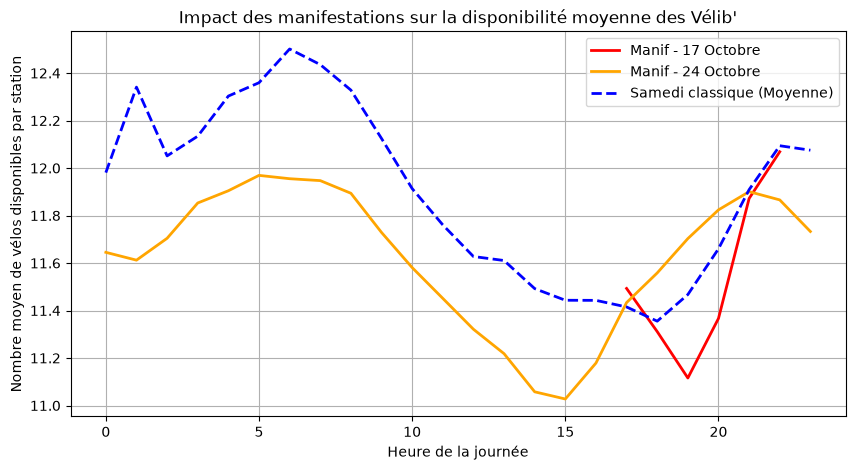

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Samedis de manifestation
plt.plot(profil_manif_17.index, profil_manif_17.values, label="Manif - 17 Octobre", color="red", linewidth=2)
plt.plot(profil_manif_24.index, profil_manif_24.values, label="Manif - 24 Octobre", color="orange", linewidth=2)

# Référence (Samedi normal)
plt.plot(profil_normal_moyen.index, profil_normal_moyen.values, label="Samedi classique (Moyenne)", color="blue", linestyle="--", linewidth=2)

plt.title("Impact des manifestations sur la disponibilité moyenne des Vélib'")
plt.xlabel("Heure de la journée")
plt.ylabel("Nombre moyen de vélos disponibles par station")
plt.legend()
plt.grid(True)
plt.show()

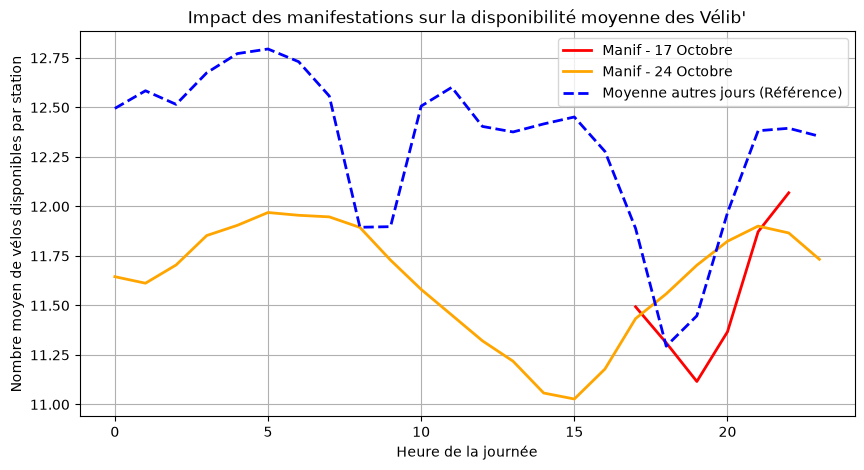

In [48]:
# 1. Isoler les samedis de manif et tous les autres jours
dates_manif = ['2026-10-17', '2026-10-24']

profil_manif_17 = df[df['date_str'] == '2026-10-17'].groupby('heure')['available'].mean()
profil_manif_24 = df[df['date_str'] == '2026-10-24'].groupby('heure')['available'].mean()

# Référence : moyenne horaire de TOUS les autres jours du dataset
profil_autres_jours = df[~df['date_str'].isin(dates_manif)].groupby('heure')['available'].mean()

# 2. Tracer le graphique avec la référence
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(profil_manif_17.index, profil_manif_17.values, label="Manif - 17 Octobre", color="red", linewidth=2)
plt.plot(profil_manif_24.index, profil_manif_24.values, label="Manif - 24 Octobre", color="orange", linewidth=2)
plt.plot(profil_autres_jours.index, profil_autres_jours.values, label="Moyenne autres jours (Référence)", color="blue", linestyle="--", linewidth=2)

plt.title("Impact des manifestations sur la disponibilité moyenne des Vélib'")
plt.xlabel("Heure de la journée")
plt.ylabel("Nombre moyen de vélos disponibles par station")
plt.legend()
plt.grid(True)
plt.show()

In [49]:
df['is_manifestation'] = df['date_str'].isin(['2026-10-17', '2026-10-24']).astype(int)

In [50]:
# date_str ne sert qu'aux graphiques ci-dessus, on ne l'exporte pas
df = df.drop(columns="date_str")

## Export du dataset nettoyé

In [51]:
SORTIE = Path("../data/clean/historique_nettoye.csv")
SORTIE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(SORTIE, index=False)